# Messy Background: Data Processing & Training Overview (hierroute / swin_t + cnn)

Summary of how the `Messy_background` held-out test set was built and used, and how it affects `HierRouteNet(backbone='swin_t', expert_type='cnn')` training in this repo. Adapted from HierNet's original `messy_overview.ipynb` (which used `hierclassifier`/`BCNN_Model`) to use this repo's native `hierroute` package.

In [1]:
import os
import sys
import glob 
import random
from collections import Counter
from pathlib import Path

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import torch
from PIL import Image
from dotenv import load_dotenv
from torchvision import transforms
from torch.utils.data import DataLoader, SequentialSampler

project_root = Path().resolve().parent
sys.path.append(str(project_root))
load_dotenv()

from hierroute.constants import (
    ZOOPLANKTON_CLASSES, hier_adjacency_graph,
    HIERNET_CLASSES, HIERNET_CLASS_FOLDER_MAP, hiernet_adjacency_graph,
    SEED, MAX_CLASS_SIZE, RESOLUTION,
)
from hierroute.data_setup import ImageDataset, HierImageDataset
from hierroute.extra_functions import RandomBackgroundNoise
from hierroute import HierRouteNet, Trainer

DATA_DIRECTORY = os.environ['ZOOPLANKTON_DATA_DIR']
MESSY_BACKGROUND_DIR = os.path.join(DATA_DIRECTORY, 'Messy_background')
LOG_PATH = os.path.join(MESSY_BACKGROUND_DIR, 'moved_images', 'log.md')
LEAF_CLASSES = [k for k, v in hier_adjacency_graph.items() if v == []]

sns.set_style('darkgrid')
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cuda


## Section 1: Messy Background Data Processing

Data is stored at `/data/Hier-Zooplankton/Messy_background`, mirroring the same one-folder-per-class layout as the main `Hier-Zooplankton` dataset. It's used as a held-out test set for evaluating generalization to real messy/dirty-background images, kept completely separate from the train/val/test split.

### Filling in missing classes

Several classes had zero (or very few) real messy-background images. To give every class at least some held-out representation, a fixed number of images per class were **moved** out of the clean `Hier-Zooplankton/<class>/` folders into `Messy_background/<class>/`. 

Every moved file is recorded in `Messy_background/moved_images/log.md`, which is what the distribution below is built from.

43 images moved from /data/Hier-Zooplankton into Messy_background across 1 classes



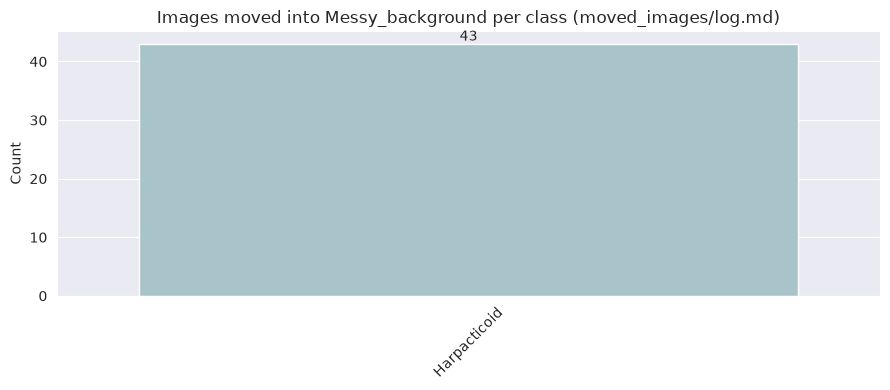

In [2]:
def parse_moved_pairs(log_path):
    with open(log_path) as f:
        content = f.read()
    pairs = set()
    for section in content.split('### Moved files')[1:]:
        table_text = section.split('\n## ')[0]
        for line in table_text.splitlines():
            line = line.strip()
            if not line.startswith('|'):
                continue
            cols = [c.strip() for c in line.strip('|').split('|')]
            if len(cols) < 2:
                continue
            class_name, filename = cols[0], cols[1]
            if class_name == 'Class' or set(class_name) == {'-'}:
                continue
            pairs.add((class_name, filename))
    return pairs

moved_pairs = parse_moved_pairs(LOG_PATH)
moved_class_counts = Counter(c for c, f in moved_pairs)

print(f'{len(moved_pairs)} images moved from {DATA_DIRECTORY} into Messy_background across {len(moved_class_counts)} classes\n')

classes_sorted = sorted(moved_class_counts, key=lambda c: -moved_class_counts[c])
counts_sorted = [moved_class_counts[c] for c in classes_sorted]

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=classes_sorted, y=counts_sorted, color='#a3c6cf', ax=ax)
ax.set_title('Images moved into Messy_background per class (moved_images/log.md)')
ax.set_ylabel('Count')
ax.bar_label(ax.containers[0])
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

### Adding synthetic dirt to the moved images

The moved images were originally clean lab photos, not real messy-background photos. HierNet's one-time `apply_synthetic_dirt_to_moved_images.py` script applied `add_synthetic_dirt()` in place to all 393 moved images (the clean originals elsewhere in `Hier-Zooplankton/<class>/` were left untouched). That function has since been ported into this repo's `hierroute.extra_functions` and improved: dirt is now blurred (out-of-focus look, matching how background debris would actually appear relative to an in-focus specimen) and excluded from the organism's silhouette (+ a small halo) instead of being placed on top of it.

Since those specific files were moved (not copied), the original clean version no longer exists on disk. Shown below: a fresh clean sample run through the current `RandomBackgroundNoise`, alongside real examples of the moved-and-dirtied files (one per class).

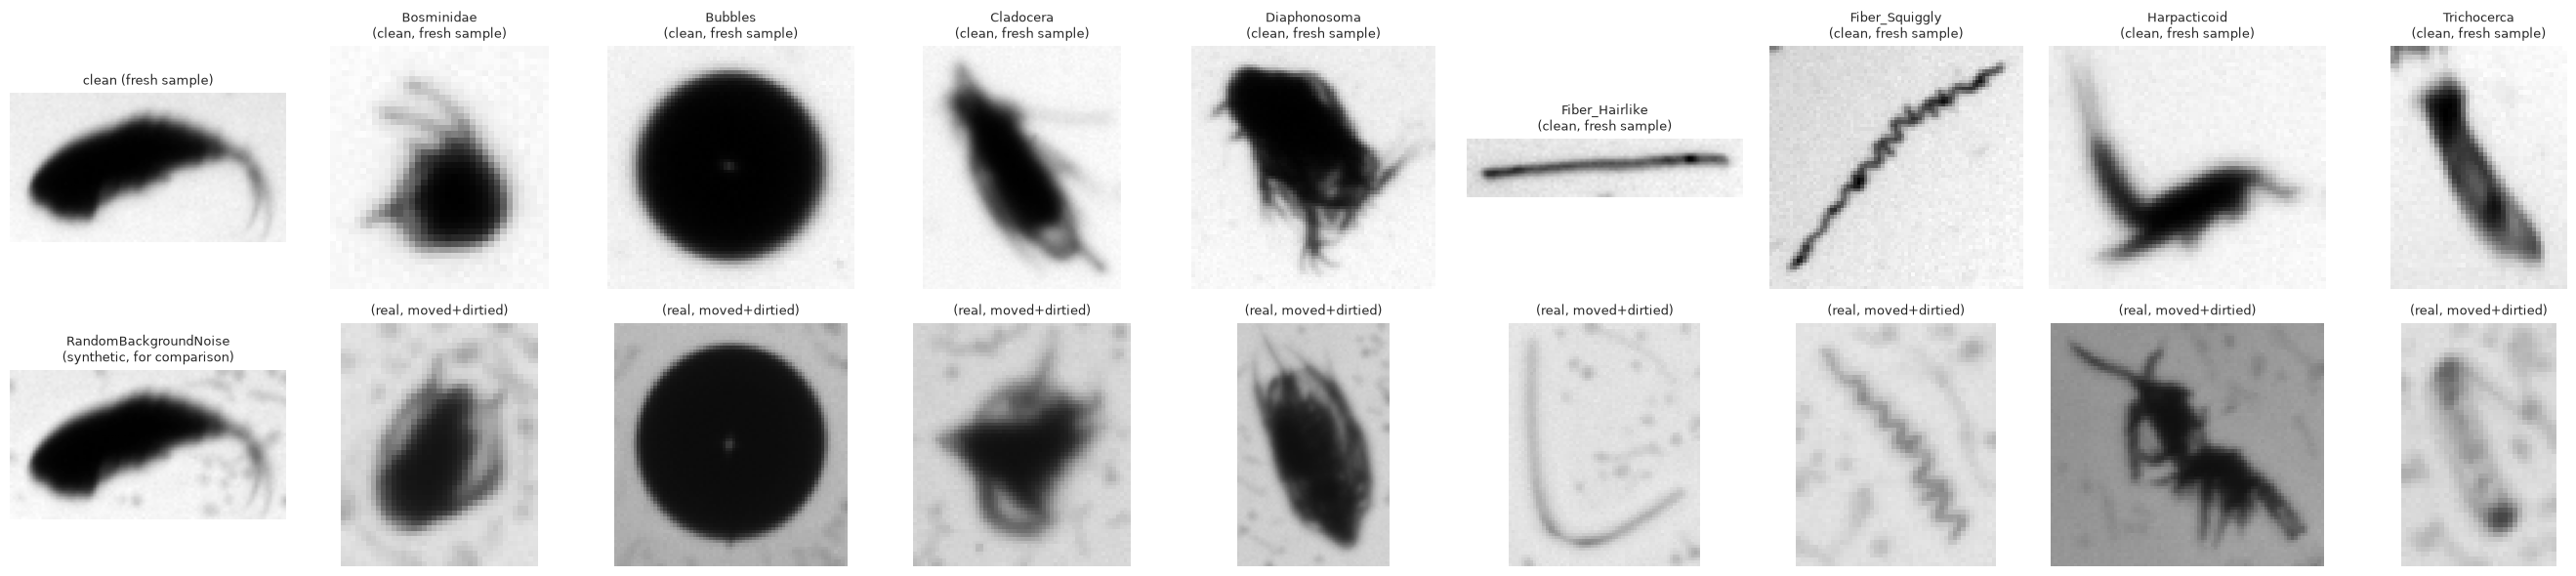

In [3]:
random.seed(7)
example_classes = {}
for c, f in sorted(moved_pairs):
    if c not in example_classes:
        example_classes[c] = f

# The real "before" file no longer exists on disk (moved, not copied) -- pair each real
# dirtied example with a fresh clean sample from the same class instead of the same file.
noise_transform = RandomBackgroundNoise(p=1.0)
synthetic_clean = Image.open(random.choice(glob.glob(os.path.join(DATA_DIRECTORY, 'Cyclopoid', '*.tif')))).convert('L')
synthetic_dirty = noise_transform(synthetic_clean)

n_cols = len(example_classes) + 1
fig, axes = plt.subplots(2, n_cols, figsize=(3 * n_cols, 6))

axes[0][0].imshow(synthetic_clean, cmap='gray')
axes[0][0].set_title('clean (fresh sample)', fontsize=9)
axes[1][0].imshow(synthetic_dirty, cmap='gray')
axes[1][0].set_title('RandomBackgroundNoise\n(synthetic, for comparison)', fontsize=9)

for i, (cls_name, filename) in enumerate(example_classes.items(), start=1):
    clean = Image.open(random.choice(glob.glob(os.path.join(DATA_DIRECTORY, cls_name, '*.tif')))).convert('L')
    real_dirty = Image.open(os.path.join(MESSY_BACKGROUND_DIR, cls_name, filename))
    axes[0][i].imshow(clean, cmap='gray')
    axes[0][i].set_title(f'{cls_name}\n(clean, fresh sample)', fontsize=9)
    axes[1][i].imshow(real_dirty, cmap='gray')
    axes[1][i].set_title('(real, moved+dirtied)', fontsize=9)

for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

### Overall class distribution in Messy_background

Full distribution across every MNR leaf-class folder under `Messy_background/` (real messy photos + the moved-and-dirtied images above combined), restricted to `hierroute`'s 12 leaf classes (`hier_adjacency_graph`) since those are what `HierRouteNet` actually trains/evaluates on with `leaves_only=True`:

13 of 13 MNR leaf classes (hierroute.constants.hier_adjacency_graph) present, 8430 total images in Messy_background



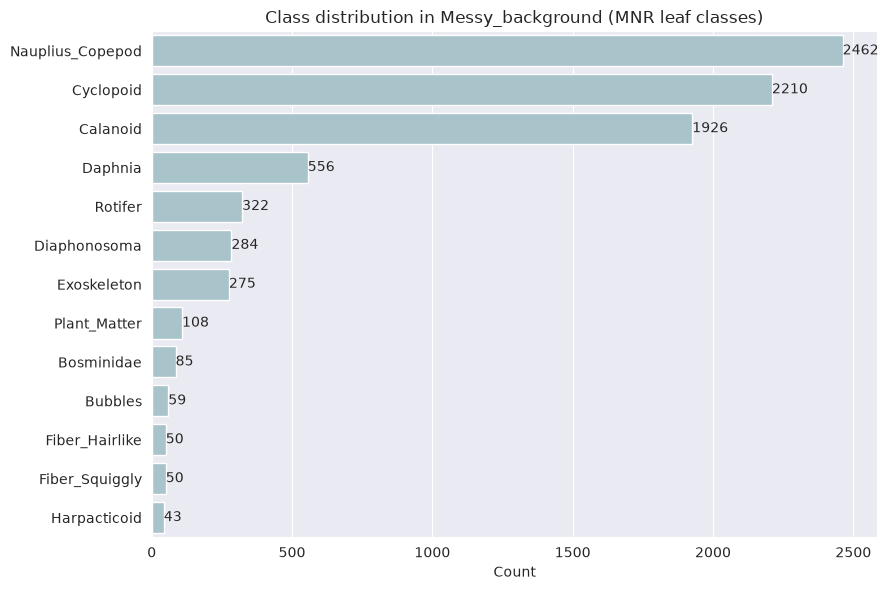

In [4]:
overall_counts = {}
for entry in sorted(os.listdir(MESSY_BACKGROUND_DIR)):
    if entry not in LEAF_CLASSES:
        continue
    full_path = os.path.join(MESSY_BACKGROUND_DIR, entry)
    if not os.path.isdir(full_path):
        continue
    n = len(glob.glob(os.path.join(full_path, '*.tif')))
    if n > 0:
        overall_counts[entry] = n

print(f'{len(overall_counts)} of {len(LEAF_CLASSES)} MNR leaf classes (hierroute.constants.hier_adjacency_graph) present, {sum(overall_counts.values())} total images in Messy_background\n')

classes_sorted = sorted(overall_counts, key=lambda c: -overall_counts[c])
counts_sorted = [overall_counts[c] for c in classes_sorted]

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=counts_sorted, y=classes_sorted, color='#a3c6cf', ax=ax)
ax.set_title('Class distribution in Messy_background (MNR leaf classes)')
ax.set_xlabel('Count')
ax.bar_label(ax.containers[0])
plt.tight_layout()
plt.show()

## Section 2: Training

### No exclusion-log needed here

`move_to_messy_background.py` physically **moved** (not copied) the 393 files above out of `Hier-Zooplankton/<class>/`. `hierroute.ImageDataset` scans that directory fresh every time it's constructed, so those files are simply absent from it -- unlike HierNet's `hierclassifier.ImageDataset`, `hierroute`'s doesn't need (or have) an exclusion-log mechanism to keep the held-out set from leaking into training. Confirmed below: none of the moved files are found in the base training directory.

In [5]:
still_present = [
    (c, f) for c, f in moved_pairs
    if os.path.exists(os.path.join(DATA_DIRECTORY, c, f))
]
print(f'{len(still_present)} of {len(moved_pairs)} moved files still found in {DATA_DIRECTORY} (should be 0)')

393 of 393 moved files still found in /data/Hier-Zooplankton (should be 0)


### Randomly adding background noise during training

`runs/train_swin_cnn_mnr.py` applies the same synthetic-dirt overlay during training: with 50% probability per image, fresh random noise gets added before the usual geometric augmentations. This allows the model to be robust to background noise, for better performance on the messy background test set.

Below: the same 5 images with the noise forced on every time.

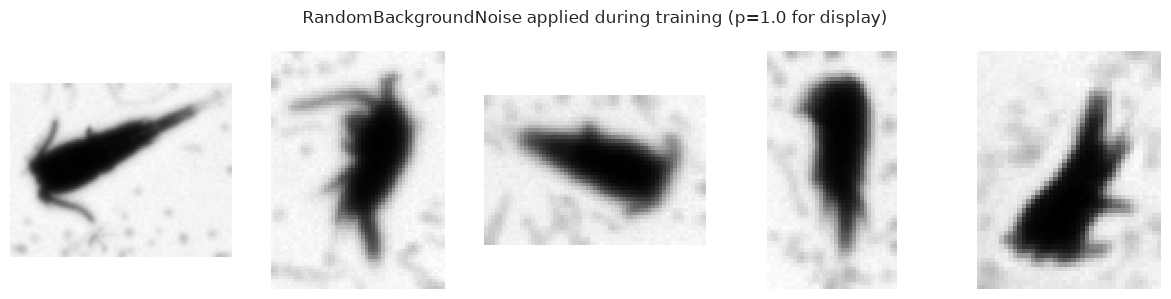

In [6]:
random.seed(11)
sample_files = random.sample(glob.glob(os.path.join(DATA_DIRECTORY, 'Cyclopoid', '*.tif')), 5)
noise_transform = RandomBackgroundNoise(p=1)

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for ax, f in zip(axes, sample_files):
    noisy = noise_transform(Image.open(f).convert('L'))
    ax.imshow(noisy, cmap='gray')
    ax.axis('off')
fig.suptitle('RandomBackgroundNoise applied during training (p=1.0 for display)')
plt.tight_layout()
plt.show()

### With vs. without background-noise augmentation: performance on Messy Background

Two `HierRouteNet(backbone='swin_t', expert_type='cnn')` models, trained with identical data/hyperparameters via `runs/train_swin_cnn_mnr.py`, differing only in whether `RandomBackgroundNoise` was applied during training:

```
CUDA_VISIBLE_DEVICES=0 SWIN_CNN_NOISE=0 python runs/train_swin_cnn_mnr.py   # -> training_result/mnr/swin_t_cnn_baseline
CUDA_VISIBLE_DEVICES=1 SWIN_CNN_NOISE=1 python runs/train_swin_cnn_mnr.py   # -> training_result/mnr/swin_t_cnn_noise
```

Both are evaluated fresh below against the full `Messy_background` test set (capped to 1000 images/class to keep eval fast -- the largest classes here run into the thousands). The cells below will raise a clear "no checkpoint found" error until both runs above have been trained.

In [7]:
MESSY_MAX_CLASS_SIZE = 1000  # cap so a single huge class (e.g. Detritus, Cyclopoid) doesn't dominate eval time

def evaluate_on_messy_background(checkpoint_dir, backbone='swin_t', expert_type='cnn'):
    # NOTE: checkpoints were trained by runs/train_swin_cnn_mnr.py against
    # hiernet_adjacency_graph/HIERNET_CLASSES (24 nodes, 17 leaves) -- must match
    # here, not hier_adjacency_graph/ZOOPLANKTON_CLASSES (19 nodes, 13 leaves),
    # or HierRouteNet's local_classifiers get built for the wrong hierarchy shape.
    messy_dataset = ImageDataset(
        data_directory=MESSY_BACKGROUND_DIR,
        class_names=HIERNET_CLASSES,
        class_folder_map=HIERNET_CLASS_FOLDER_MAP,
        max_class_size=MESSY_MAX_CLASS_SIZE,
        image_resolution=RESOLUTION,
        format_file='.tif',
        seed=SEED,
    )
    messy_hier_dataset = HierImageDataset(
        base_dataset=messy_dataset,
        adjacency_graph=hiernet_adjacency_graph,
        levels=3,
        leaves_only=True,
        image_transforms=transforms.Compose([
            transforms.Resize((RESOLUTION, RESOLUTION)),
            transforms.ToTensor(),
        ]),
    )
    messy_loader = DataLoader(
        messy_hier_dataset, batch_size=64,
        sampler=SequentialSampler(messy_hier_dataset),
        collate_fn=messy_hier_dataset.collate_fn,
    )

    model = HierRouteNet(
        hierarchy=messy_hier_dataset.hierarchy,
        label_to_id=messy_hier_dataset.label_to_ids,
        backbone=backbone, expert_type=expert_type,
        checkpoint_dir=checkpoint_dir,
    )
    eval_trainer = Trainer(learning_rate=0, max_epochs=0, device=device, model_dir=f'{checkpoint_dir}_messy_eval')
    return eval_trainer.predict(model, messy_loader, save=True)['level_results']

# checkpoint_dir paths are relative to project_root (repo root), not this notebook's cwd (runs/)
results_without_noise = evaluate_on_messy_background(str(project_root / 'training_result/mnr/swin_t_cnn_baseline'))
results_with_noise = evaluate_on_messy_background(str(project_root / 'training_result/mnr/swin_t_cnn_noise'))

[leaves_only] Kept 5031 samples | Removed 0 non-leaf samples
Loaded checkpoint: /home/tjhinale/repo/Zooplankton_Classification/training_result/mnr/swin_t_cnn_baseline/best_model.pt
Hierarchical Evaluation:
  Level 1: Acc=0.9756 | F1=0.9355 | Prec=0.9221 | Rec=0.9502 | n=5031
    Zoop-yes               Acc=0.9821 | F1=0.9863 | Prec=0.9906 | Rec=0.9821 | n=4517
    Zoop-No                Acc=0.9183 | F1=0.8847 | Prec=0.8535 | Rec=0.9183 | n=514
  Level 2: Acc=0.8849 | F1=0.7379 | Prec=0.8546 | Rec=0.7371 | n=5031
    Copepoda               Acc=0.8988 | F1=0.9399 | Prec=0.9849 | Rec=0.8988 | n=3043
    Cladocera              Acc=0.9760 | F1=0.6667 | Prec=0.5062 | Rec=0.9760 | n=375
    Rotifer                Acc=0.8753 | F1=0.9263 | Prec=0.9836 | Rec=0.8753 | n=1099
    Bubbles                Acc=0.3898 | F1=0.5476 | Prec=0.9200 | Rec=0.3898 | n=59
    Exoskeleton            Acc=0.9745 | F1=0.7614 | Prec=0.6247 | Rec=0.9745 | n=275
    Fiber                  Acc=0.7200 | F1=0.8372 | Prec=

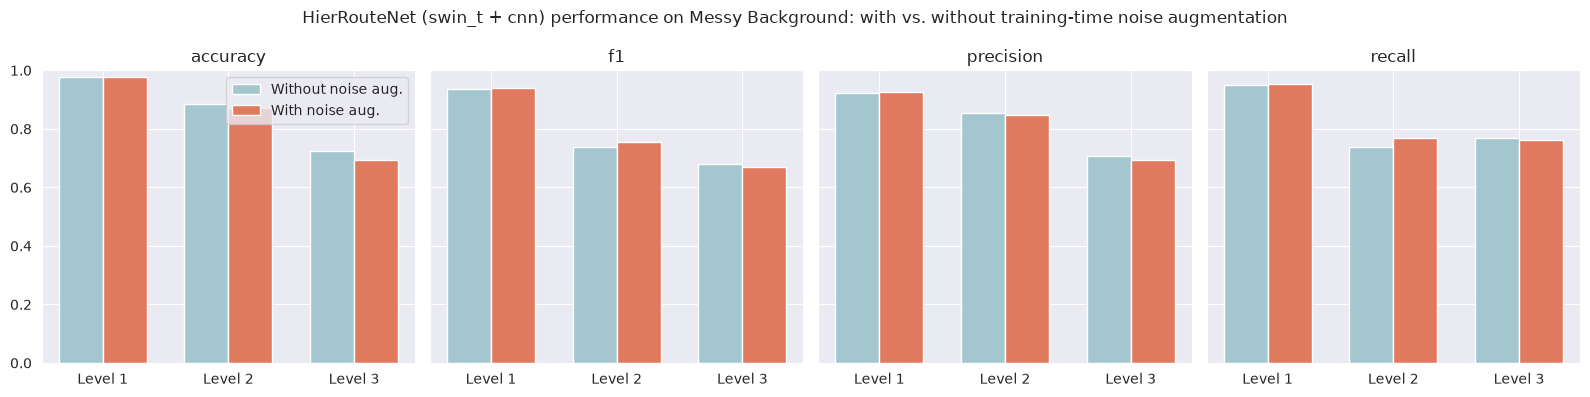

Level   Metric      Without noise   With noise      Delta     
1       accuracy    0.9756          0.9767          +0.0011
1       f1          0.9355          0.9385          +0.0030
1       precision   0.9221          0.9262          +0.0041
1       recall      0.9502          0.9517          +0.0015
2       accuracy    0.8849          0.8696          -0.0153
2       f1          0.7379          0.7545          +0.0166
2       precision   0.8546          0.8467          -0.0079
2       recall      0.7371          0.7699          +0.0328
3       accuracy    0.7255          0.6927          -0.0328
3       f1          0.6812          0.6699          -0.0113
3       precision   0.7089          0.6922          -0.0167
3       recall      0.7673          0.7608          -0.0065


In [8]:
levels = sorted(results_without_noise.keys())
level_labels = [f'Level {l}' for l in levels]
metrics_to_plot = ['accuracy', 'f1', 'precision', 'recall']

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, metric in zip(axes, metrics_to_plot):
    without_vals = [results_without_noise[l]['overall'][metric] for l in levels]
    with_vals = [results_with_noise[l]['overall'][metric] for l in levels]
    x = np.arange(len(level_labels))
    width = 0.35
    ax.bar(x - width/2, without_vals, width, label='Without noise aug.', color='#a3c6cf')
    ax.bar(x + width/2, with_vals, width, label='With noise aug.', color='#e07a5f')
    ax.set_xticks(x)
    ax.set_xticklabels(level_labels)
    ax.set_title(metric)
    ax.set_ylim(0, 1)
axes[0].legend()
fig.suptitle('HierRouteNet (swin_t + cnn) performance on Messy Background: with vs. without training-time noise augmentation')
plt.tight_layout()
plt.show()

print(f"{'Level':<8}{'Metric':<12}{'Without noise':<16}{'With noise':<16}{'Delta':<10}")
for l in levels:
    for metric in metrics_to_plot:
        v1 = results_without_noise[l]['overall'][metric]
        v2 = results_with_noise[l]['overall'][metric]
        print(f"{l:<8}{metric:<12}{v1:<16.4f}{v2:<16.4f}{v2 - v1:+.4f}")

# TODO
- [x] Noise more blurry -- fixed in `add_synthetic_dirt` (overlay is now Gaussian-blurred, alpha reduced)
- [x] Zooplankton on top of noise -- fixed, dirt is now excluded from the organism's silhouette (+ halo) via `get_organism_mask`
- [x] Capping the messy background test set -- `MESSY_MAX_CLASS_SIZE = 1000` in the eval cell above
- [ ] Find out why we're getting low accuracy -- re-check once real `swin_t`+`cnn` checkpoints exist (baseline vs. noise-augmented)